# Lecture 5 Practice: K-Nearest Neighbors for Wine Classification

**Course:** Lecture 5 – ML Common Algorithms
**Algorithm:** K-Nearest Neighbors (KNN) classifier
**Dataset:** Wine recognition dataset (178 wines, 13 chemical measurements, 3 grape cultivars), built into scikit-learn

This is an individual practice assignment. It uses a different algorithm and a different dataset from the team project FLCS#1. No file upload is needed because the dataset is loaded directly from scikit-learn.

## 1. How K-Nearest Neighbors works

KNN is one of the simplest ML algorithms. It does not learn a formula during training. It just stores the training data and decides at prediction time.

1. **Choose k**, the number of neighbors to look at.
2. **Measure distance** from the new sample to every training sample (usually Euclidean distance, sqrt(sum((a_i - b_i)^2)), or Manhattan distance, sum(|a_i - b_i|)).
3. **Pick the k closest** training samples.
4. **Vote:** the predicted class is the majority class among those k neighbors (with `weights="distance"`, closer neighbors count more).

**Choosing k:** a very small k (such as 1) follows the training data too closely and is sensitive to noise (overfitting). A very large k smooths too much and ignores local patterns (underfitting).

**Why scaling is essential:** KNN is based on distance, so a feature with large numbers (such as `proline`, up to 1680) would overpower a feature with small numbers (such as `hue`, about 0.5 to 1.7). We therefore standardize every feature to mean 0 and standard deviation 1 before using KNN. This notebook shows the effect with a direct comparison.

## 2. Import libraries

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
print("Libraries imported successfully")

Libraries imported successfully


## 3. Load the dataset

In [2]:
wine = load_wine(as_frame=True)
X = wine.data
y = wine.target
class_names = list(wine.target_names)

print("Samples:", X.shape[0])
print("Features:", X.shape[1])
print("Classes:", class_names)
X.head()

Samples: 178
Features: 13
Classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## 4. Explore the data

In [3]:
print("Missing values:", X.isnull().sum().sum())
print("Duplicate rows:", X.duplicated().sum())
print()
print("Class counts:")
print(y.value_counts().sort_index())

Missing values: 0
Duplicate rows: 0

Class counts:
target
0    59
1    71
2    48
Name: count, dtype: int64


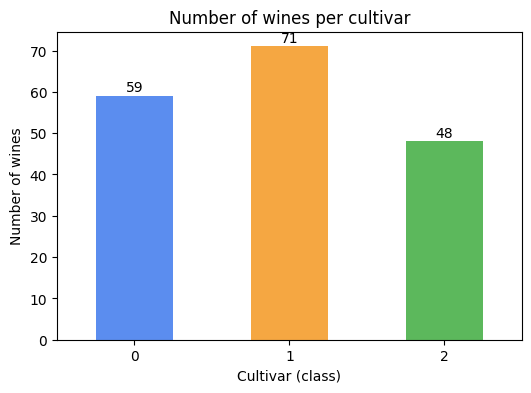

In [4]:
counts = y.value_counts().sort_index()
ax = counts.plot(kind="bar", figsize=(6, 4), color=["#5b8def", "#f5a742", "#5cb85c"])
plt.title("Number of wines per cultivar")
plt.xlabel("Cultivar (class)")
plt.ylabel("Number of wines")
plt.xticks(rotation=0)
for i, v in enumerate(counts):
    ax.text(i, v + 1, str(v), ha="center")
plt.show()

In [5]:
summary = X.describe().loc[["min", "max", "mean", "std"]].T.round(2)
summary

,min,max,mean,std
alcohol,11.03,14.83,13.00,0.81
malic_acid,0.74,5.80,2.34,1.12
ash,1.36,3.23,2.37,0.27
alcalinity_of_ash,10.60,30.00,19.49,3.34
magnesium,70.00,162.00,99.74,14.28
total_phenols,0.98,3.88,2.30,0.63
flavanoids,0.34,5.08,2.03,1.00
nonflavanoid_phenols,0.13,0.66,0.36,0.12
proanthocyanins,0.41,3.58,1.59,0.57
color_intensity,1.28,13.00,5.06,2.32


**Observations:** there are no missing values or duplicates, and the three classes are reasonably balanced (59, 71 and 48 wines). The feature ranges are very different: `proline` goes up to 1680 while `hue` stays between about 0.5 and 1.7. This is exactly the situation where KNN needs scaling.

## 5. Visualize the classes

We project the 13 features onto 2 dimensions with PCA, only to look at how well the cultivars separate. PCA is not used in the model.

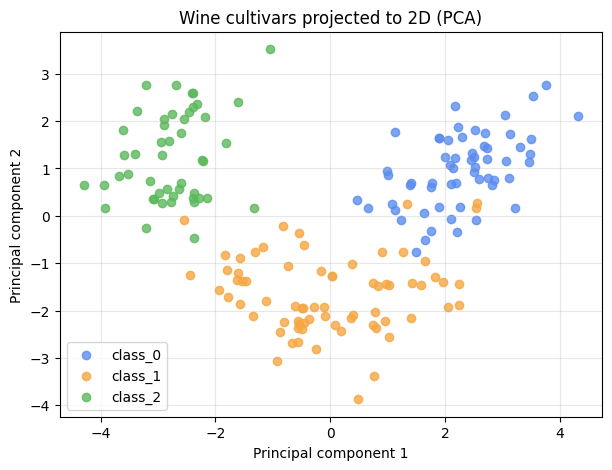

In [6]:
X_scaled_all = StandardScaler().fit_transform(X)
pcs = PCA(n_components=2).fit_transform(X_scaled_all)

plt.figure(figsize=(7, 5))
for label, color in zip([0, 1, 2], ["#5b8def", "#f5a742", "#5cb85c"]):
    mask = (y == label).values
    plt.scatter(pcs[mask, 0], pcs[mask, 1], c=color, label=class_names[label], alpha=0.8)
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("Wine cultivars projected to 2D (PCA)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The three cultivars form fairly clear groups, which is a good sign for a distance-based method like KNN.

## 6. Train/test split

We keep 20% of the data for testing and use `stratify=y` so each class has the same proportion in both parts. The test set is small (36 wines), so we also use cross-validation later.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 142
Testing samples: 36


## 7. Why scaling matters: KNN without and with scaling

Both models use k = 5. The only difference is standardization. The scaler is fitted on the training data only, inside a pipeline, to avoid data leakage.

In [8]:
knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_raw.fit(X_train, y_train)

knn_scaled = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
])
knn_scaled.fit(X_train, y_train)

print("Without scaling -> train:", round(knn_raw.score(X_train, y_train), 4), " test:", round(knn_raw.score(X_test, y_test), 4))
print("With scaling    -> train:", round(knn_scaled.score(X_train, y_train), 4), " test:", round(knn_scaled.score(X_test, y_test), 4))

Without scaling -> train: 0.7817  test: 0.8056
With scaling    -> train: 0.9789  test: 0.9722


Scaling is the biggest improvement in this notebook: test accuracy rises from about 80.6% without scaling to about 97.2% with scaling. Without it, `proline` and `magnesium` dominate the distance, and the other features are almost ignored.

## 8. Effect of k

We try odd values of k from 1 to 31 and compare training and testing accuracy.

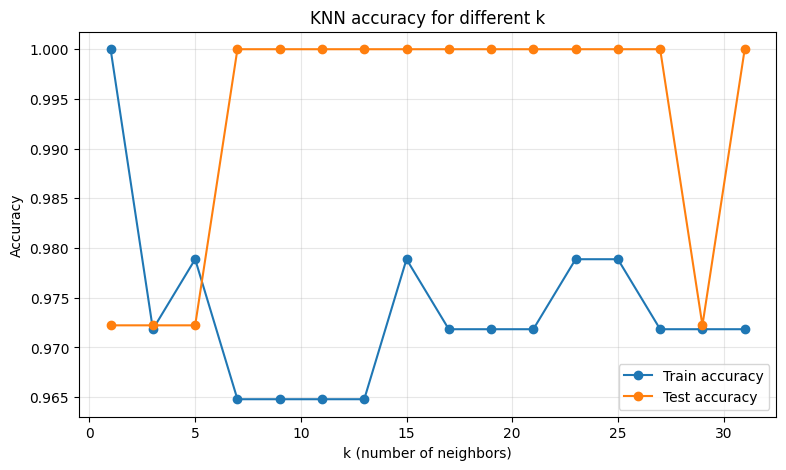

k= 1  train=1.0000  test=0.9722
k= 3  train=0.9718  test=0.9722
k= 5  train=0.9789  test=0.9722
k= 7  train=0.9648  test=1.0000
k= 9  train=0.9648  test=1.0000
k=11  train=0.9648  test=1.0000
k=13  train=0.9648  test=1.0000
k=15  train=0.9789  test=1.0000
k=17  train=0.9718  test=1.0000
k=19  train=0.9718  test=1.0000
k=21  train=0.9718  test=1.0000
k=23  train=0.9789  test=1.0000
k=25  train=0.9789  test=1.0000
k=27  train=0.9718  test=1.0000
k=29  train=0.9718  test=0.9722
k=31  train=0.9718  test=1.0000


In [9]:
k_values = list(range(1, 32, 2))
train_scores = []
test_scores = []

for k in k_values:
    model_k = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])
    model_k.fit(X_train, y_train)
    train_scores.append(model_k.score(X_train, y_train))
    test_scores.append(model_k.score(X_test, y_test))

plt.figure(figsize=(9, 5))
plt.plot(k_values, train_scores, marker="o", label="Train accuracy")
plt.plot(k_values, test_scores, marker="o", label="Test accuracy")
plt.xlabel("k (number of neighbors)")
plt.ylabel("Accuracy")
plt.title("KNN accuracy for different k")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

for k, tr, te in zip(k_values, train_scores, test_scores):
    print(f"k={k:2d}  train={tr:.4f}  test={te:.4f}")

With k = 1 the training accuracy is a perfect 100% because every training sample is its own nearest neighbor, which does not show real quality. For larger k the training accuracy drops slightly (to about 96 to 98%), while the test accuracy stays high. Because the test set has only 36 samples, one wine changes the accuracy by about 2.8 points, so we should not read too much into small differences between k values.

## 9. Tune the hyperparameters with GridSearchCV

We use 5-fold stratified cross-validation on the training set only, so the test set stays untouched. We tune k, the voting weights and the distance metric.

In [10]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier()),
])

param_grid = {
    "knn__n_neighbors": list(range(1, 26)),
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validation accuracy:", round(grid.best_score_, 4))

Best parameters: {'knn__metric': 'manhattan', 'knn__n_neighbors': 7, 'knn__weights': 'uniform'}
Best cross-validation accuracy: 0.9788


## 10. Evaluate the final model on the test set

In [11]:
model = grid.best_estimator_
y_pred = model.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=class_names))

Test accuracy: 1.0

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



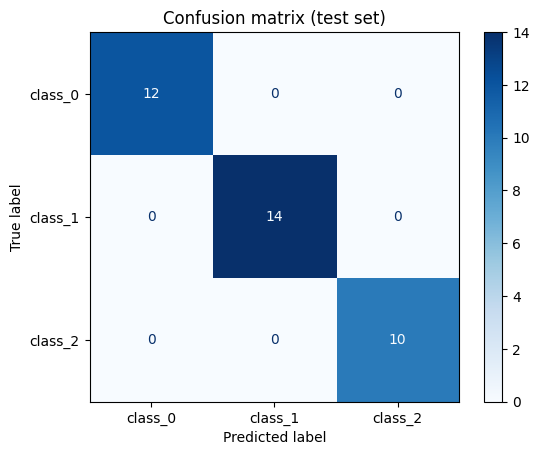

In [12]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix (test set)")
plt.show()

The tuned model classifies all 36 test wines correctly. The cross-validation accuracy on the training data was about 97.9%, so the realistic expectation for new wines is around 97 to 98%, not necessarily 100%. A perfect test score on only 36 samples is partly luck, which is why the next section double-checks with cross-validation.

## 11. Cross-validation on the full dataset

This gives a more reliable estimate than one small test split.

In [13]:
scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
print("Fold accuracies:", np.round(scores, 4))
print("Mean accuracy  :", round(scores.mean(), 4))
print("Std deviation  :", round(scores.std(), 4))

Fold accuracies: [0.9444 1.     1.     0.9429 1.    ]
Mean accuracy  : 0.9775
Std deviation  : 0.0276


The mean accuracy over 5 folds is about 97.7%, with every fold between 94% and 100%. This confirms that the model works well and consistently.

## 12. Predict a new wine

In [14]:
sample = X_test.iloc[[0]]
predicted = model.predict(sample)[0]
probabilities = model.predict_proba(sample)[0]

print("Actual cultivar   :", class_names[y_test.iloc[0]])
print("Predicted cultivar:", class_names[predicted])
for name, p in zip(class_names, probabilities):
    print(f"Probability {name}: {p:.2f}")

Actual cultivar   : class_0
Predicted cultivar: class_0
Probability class_0: 1.00
Probability class_1: 0.00
Probability class_2: 0.00


## 13. Conclusion

- KNN classifies a sample by looking at its k nearest training samples and taking a vote. It needs no training phase, but every prediction compares the sample with all stored data.
- Because it depends on distance, feature scaling is essential: standardizing the features raised test accuracy from about 80.6% to about 97.2% in this notebook.
- The choice of k matters: k = 1 memorizes the training data, while moderate values of k give a more stable model.
- GridSearchCV with cross-validation chose the best k, weighting and distance metric without using the test set.
- The final model scored 100% on the 36-sample test set and about 97.7% in 5-fold cross-validation, so it is accurate and consistent for this dataset.
- **Limitations:** KNN becomes slow on large datasets, is sensitive to irrelevant features, and always needs scaling. The Wine dataset is small and clean, so results on real-world data would likely be lower.